# FMAPIq N=200 test example

SAXS I(q) of a concentrated protein solution (cenA, 1959 atoms; N = 200 proteins in a 619.65 Å box,
0.016 M ions, 25 °C) from FMAP energy maps, NVT Monte Carlo and a Debye-type scattering calculation.

Run this notebook with a Julia kernel (`IJulia`) started from this directory, or open it in Google Colab:

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zhougroup-uic/FMAPIqJ/blob/main/examples/n200_test/n200_test.ipynb)

On Colab pick a **GPU runtime** (Runtime → Change runtime type → T4); the first cell below clones the repository.
Switch `MODE` below: **`"gpu"`** = all stages on the GPU with 64 independent runs (about 4 min on an L40, about 10 min on a Colab T4),
**`"cpu"`** = CPU engines with 3 runs (much slower: the CPU energy maps alone take about 20 min).

> **Kernel:** locally, if Jupyter does not list a Julia kernel, run `julia tools/notebook.jl install` once
> (installs IJulia and a kernel `julia` started with `--project=<repo>`), or `julia tools/notebook.jl` to install and launch Jupyter.

## 0. Get the code (Colab / standalone notebook only)
Skipped when the notebook is run from inside a clone of the repository.

In [1]:
# Colab / fresh machine: fetch the repository when the notebook was opened without it
let d = pwd(), found = false
    while true
        isfile(joinpath(d, "bin", "fmapiq.jl")) && (found = true; break)
        dirname(d) == d && break
        d = dirname(d)
    end
    if !found
        repo = joinpath(isdir("/content") ? "/content" : pwd(), "FMAPIqJ")
        isdir(repo) || run(`git clone --depth 1 https://github.com/zhougroup-uic/FMAPIqJ $repo`)
        println("code version: ", readchomp(`git -C $repo rev-parse --short HEAD`))
        cd(joinpath(repo, "examples", "n200_test"))
    end
    println("working directory: ", pwd())
end

Cloning into '/content/FMAPIqJ'...


code version: 6acd881
working directory: /content/FMAPIqJ/examples/n200_test


## 1. Settings

In [2]:
# "gpu" (64 runs) or "cpu" (3 runs); `nothing` = gpu if nvidia-smi sees a device, else cpu
MODE = nothing

has_gpu() = Sys.which("nvidia-smi") !== nothing && success(pipeline(`nvidia-smi -L`; stdout = devnull, stderr = devnull))
mode = something(MODE, has_gpu() ? "gpu" : "cpu")
mode in ("gpu", "cpu") || error("MODE must be \"gpu\" or \"cpu\"")
mode == "cpu" && haskey(ENV, "COLAB_RELEASE_TAG") &&
    @warn "no GPU visible: choose Runtime -> Change runtime type -> GPU, or CPU mode takes ~20 min for the energy maps"

NREPS    = mode == "gpu" ? 64 : 3          # independent runs
NCYCLES  = 20000                           # Monte Carlo cycles per run
THREADS  = 8                               # CPU threads (CPU mode / host work)

# repository root: the directory with bin/fmapiq.jl above the notebook
ROOT = let d = pwd()
    while !isfile(joinpath(d, "bin", "fmapiq.jl")) && dirname(d) != d; d = dirname(d); end
    d
end
WORK = joinpath(ROOT, "examples", "n200_test", "work_notebook_$(mode)")
println("mode = $mode, runs = $NREPS, cycles = $NCYCLES\nroot = $ROOT\nwork = $WORK")

mode = gpu, runs = 64, cycles = 20000
root = /content/FMAPIqJ
work = /content/FMAPIqJ/examples/n200_test/work_notebook_gpu


## 2. Install packages (first time only)
Instantiates the project environment of the repository (downloads the Julia packages).

In [3]:
using Pkg
Pkg.activate(ROOT)
Pkg.instantiate()

  Activating project at `/content/FMAPIqJ`
    Updating registry at `~/.julia/registries/General.toml`
   Installed Adapt ────────────────── v4.7.4
   Installed oneTBB_jll ───────────── v2023.1.0+0
   Installed FFTW ─────────────────── v1.10.0
   Installed cuFFT ────────────────── v6.4.2
   Installed NVML ─────────────────── v6.4.2
   Installed cuSOLVER ─────────────── v6.4.2
   Installed CUPTI ────────────────── v6.4.2
   Installed MKL_jll ──────────────── v2025.2.0+0
   Installed GPUCompiler ──────────── v2.14.1
   Installed StaticArrays ─────────── v1.9.23
   Installed LLVMExtra_jll ────────── v0.0.53+0
   Installed OrderedCollections ───── v2.0.3
   Installed CUDACore ─────────────── v6.4.2
   Installed IntelOpenMP_jll ──────── v2025.2.0+0
   Installed CUDA_Compiler_jll ────── v0.6.3+2
   Installed CUDATools ────────────── v6.4.2
   Installed MSVCRuntime_jll ──────── v14.51.36247+0
   Installed GPUToolbox ───────────── v3.3.3
   Installed cuSPARSE ─────────────── v6.4.2
   Installe

## 3. Run the pipeline
`bin/fmapiq.jl` runs the three stages in sequence: energy maps (`fmappre` → `fmap` → `fmapstat`),
NVT simulations, and P(q)/I(q) with statistics and plot. Output is streamed below.

In [4]:
rm(WORK; recursive = true, force = true)
mkpath(joinpath(WORK, "cache"))
cp(joinpath(ROOT, "examples", "cenA.pqr"), joinpath(WORK, "subA.pqr"))

args = [joinpath(ROOT, "bin", "fmapiq.jl"), "subA.pqr", "--work-dir", "run",
        "--threads", string(THREADS), "--sim-threads", "2",
        "--n-reps", string(NREPS), "--n-cycles", string(NCYCLES),
        "--ion", "0.016", "--temp", "25", "--vscl", "0.16",
        "--n-proteins", "200", "--box-size", "619.65"]
mode == "gpu" && push!(args, "--gpu")
env = merge(ENV, Dict("FMAPIQ_CACHE" => joinpath(WORK, "cache")))
t = @elapsed run(setenv(`$(Base.julia_exename()) --project=$ROOT $args`, env; dir = WORK))
println("pipeline wall time: ", round(t / 60; digits = 2), " min")

Loaded existing work directory: /content/FMAPIqJ/examples/n200_test/work_notebook_gpu/run
Stage 1: Not completed
Stage 2: Not completed
Stage 3: Not completed
Running Stage 1: Energy map calculation...
Stage 1 Complete!
Temperature  :   2.98150000E+02 K
kbt          :   5.92079218E-01
ion          :   1.60000000E-02 M
qscl         :   1.13070494E+00
sdie         :   7.83033437E+01
kappa        :   4.16327574E-02
lambda       :   2.40195477E+01 angstrom
rscl         :            1.080
escl         :            1.000
vscl         :            0.160
ChargeA      :                7
MassA        :        14314.240 Da
MaxRA        :           26.515 angstrom
mass         :        14314.240 Da
MaxR         :           26.515 angstrom
rcut         :           72.000 angstrom
spacing      :              0.6
blen         :              430
nrot         : 72
FMAPvs       :     1015117.290 angstrom^3
FMAPb22      :          14.918 x 10^-4 mL mol / g^2
FMAPb22std   :          0.0091 x 10^-4 mL mol 

## 4. Results

In [5]:
using DelimitedFiles, Printf
RUN = joinpath(WORK, "run")
iqs  = readdlm(joinpath(RUN, "Iqs.txt"), Float64; comments = true)       # q, P(q), I_1/n ... I_R/n
stat = readdlm(joinpath(RUN, "Iqs.stat.txt"), Float64; comments = true)  # q, P/P0, mean/P0, SEM
@printf("P(0) = %.6e   (expected 2.186e6)\n", iqs[1, 2])
@printf("%d runs, %d q points, q = %.4f .. %.3f 1/A\n", size(iqs, 2) - 2, size(iqs, 1), iqs[2, 1], iqs[end, 1])

P(0) = 2.186413e+06   (expected 2.186e6)
64 runs, 308 q points, q = 0.0144 .. 3.118 1/A


In [6]:
# table of the first points: q, P(q)/P0, mean I(q)/P0 and its standard error over the runs
println("      q        P(q)/P0    I(q)/P0     SEM")
for i in (2, 5, 10, 20, 40, 80, 160, size(stat, 1))
    @printf("%8.4f  %10.5f  %10.5f  %10.5f\n", stat[i, 1], stat[i, 2], stat[i, 3], stat[i, 4])
end

      q        P(q)/P0    I(q)/P0     SEM
  0.0144     0.98479     0.52494     0.01927
  0.0449     0.86438     0.64590     0.00630
  0.0959     0.51094     0.51631     0.00265
  0.1975     0.05338     0.05319     0.00011
  0.4004     0.01346     0.01358     0.00002
  0.8060     0.00550     0.00564     0.00000
  1.6173     0.00944     0.00935     0.00000
  3.1180     0.00747     0.00710     0.00000


The pipeline also writes `iq_plot.svg` (individual runs, mean ± SEM and the form factor P(q)):

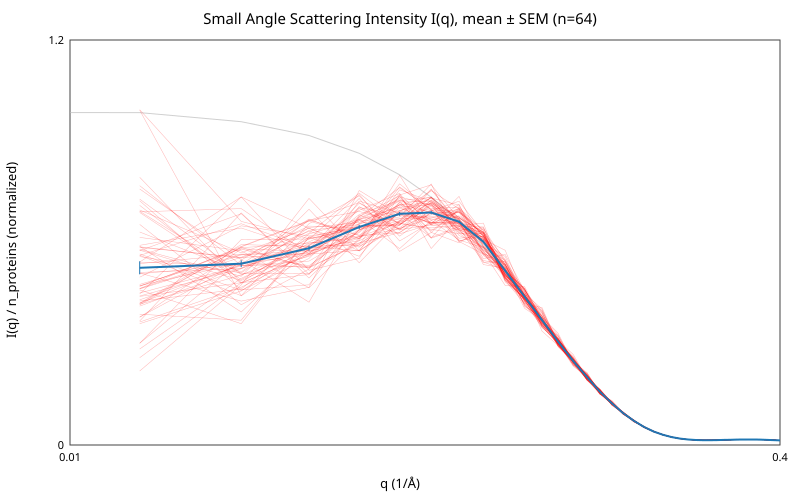

In [7]:
svg = read(joinpath(RUN, "iq_plot.svg"), String)
display("image/svg+xml", svg)

## 5. Check against the stored reference
`expected/Iqs.stat.n<runs>.txt` holds the result of the reference run with the same number of runs.
`tools/check_result.jl` passes if the mean curve agrees within 5 % or 3 standard errors.

In [8]:
expected = joinpath(ROOT, "examples", "n200_test", "expected", "Iqs.stat.n$(NREPS).txt")
if NCYCLES == 20000 && isfile(expected)
    run(`$(Base.julia_exename()) --project=$ROOT $(joinpath(ROOT, "tools", "check_result.jl")) $(joinpath(RUN, "Iqs.stat.txt")) $expected 0.05`)
else
    println("no reference for NREPS = $NREPS, NCYCLES = $NCYCLES")
end

q grid max diff 0.00e+00 | P(q)/P0 max rel diff 9.86e-07 | mean/P0 max rel diff 0.000 | outside tolerance: 0 of 38 points
PASS


Process(`julia --project=/content/FMAPIqJ /content/FMAPIqJ/tools/check_result.jl /content/FMAPIqJ/examples/n200_test/work_notebook_gpu/run/Iqs.stat.txt /content/FMAPIqJ/examples/n200_test/expected/Iqs.stat.n64.txt 0.05`, ProcessExited(0))